# PA-3 — Questions 1–2

## Question 1 – What does a sum remember?

A neighbourhood is described by three counts: `n_slow` (−1), `n_steady` (0) and `n_fast` (+1).
Then $n_v$ = `n_slow + n_steady + n_fast` and $S_v$ = `n_fast - n_slow`.

In [1]:
import numpy as np
from itertools import product

def make_neighbourhood(n_slow, n_steady, n_fast):
    # e.g. (2, 1, 0) -> [-1, -1, 0]
    return [-1] * n_slow + [0] * n_steady + [1] * n_fast

# Every possible (n_slow, n_steady, n_fast) with 1 to 8 neighbours in total
all_combos = product(range(9), repeat=3)
all_hoods = [counts for counts in all_combos if 1 <= sum(counts) <= 8]

print("Number of possible neighbourhoods :", len(all_hoods))

Number of possible neighbourhoods : 164


### (a) Affine message $\phi(x) = wx + c$

$$\sum_{u} (w x_u + c) = w S_v + c\, n_v \quad\Rightarrow\quad h_v = \rho(w S_v + c\, n_v)$$

ρ only sees $w S_v + c\, n_v$. If two neighbourhoods have the same $n_v$ and $S_v$, ρ gets the same input, so the output is the same for any $w$, $c$ and ρ.

Example: {−1, +1, 0, 0, −1} and {−1, 0, 0, 0, 0} both have $n_v = 5$, $S_v = -1$, but 2 vs 4 steady neighbours.

In [2]:
N1 = np.array([-1, 1, 0, 0, -1])
N2 = np.array([-1, 0, 0, 0, 0])

# Try a few random w, c values
for w, c in [(0.5, 2.0), (-1.3, 0.7), (3.0, -4.0)]:
    sum1 = np.sum(w * N1 + c)
    sum2 = np.sum(w * N2 + c)
    same = np.isclose(sum1, sum2)
    print(f"w={w}, c={c}: N1 = {sum1:.2f}, N2 = {sum2:.2f}, same : {same}")

print("Steady neighbours :", np.sum(N1 == 0), "vs", np.sum(N2 == 0))

w=0.5, c=2.0: N1 = 9.50, N2 = 9.50, same : True
w=-1.3, c=0.7: N1 = 4.80, N2 = 4.80, same : True
w=3.0, c=-4.0: N1 = -23.00, N2 = -23.00, same : True
Steady neighbours : 2 vs 4


### (b) Place-value message

Use base $B = K + 1$: **φ(−1) = 1, φ(0) = B, φ(+1) = B²**, so

$$\text{sum} = n_{slow} + n_{steady} \cdot B + n_{fast} \cdot B^2$$

Each count is at most $K < B$, so it fits in one base-$B$ digit without carrying, and every neighbourhood gets a different sum. A smaller base fails because a count of $K$ would carry into the next digit.

Decode: `n_slow = total % B`, `n_steady = (total // B) % B`, `n_fast = total // (B * B)`.

**K = 8:** φ(−1) = 1, φ(0) = 9, φ(+1) = 81.

In [3]:
K = 8
B = K + 1
phi = {-1: 1, 0: B, 1: B * B}
print(f"phi(-1) = {phi[-1]}, phi(0) = {phi[0]}, phi(+1) = {phi[1]}")

seen_sums = set()
all_decoded_ok = True

for counts in all_hoods:
    hood = make_neighbourhood(*counts)
    # sum of the neighbours' messages
    total = sum(phi[x] for x in hood)
    seen_sums.add(total)

    decoded = (total % B, (total // B) % B, total // (B * B))
    if decoded != counts:
        all_decoded_ok = False
        print("Decode failed for :", counts)

print("Neighbourhoods checked :", len(all_hoods))
print("Different sums found :", len(seen_sums))
print("Every sum is unique :", len(seen_sums) == len(all_hoods))
print("Every decode correct :", all_decoded_ok)

phi(-1) = 1, phi(0) = 9, phi(+1) = 81
Neighbourhoods checked : 164
Different sums found : 164
Every sum is unique : True
Every decode correct : True


In [4]:
# What goes wrong with a base that is too small (B = 8 instead of 9)?
bad_B = 8
bad_phi = {-1: 1, 0: bad_B, 1: bad_B * bad_B}

eight_steady = make_neighbourhood(0, 8, 0)
one_fast = make_neighbourhood(0, 0, 1)
print("Sum for 8 steady neighbours :", sum(bad_phi[x] for x in eight_steady))
print("Sum for 1 speeding neighbour :", sum(bad_phi[x] for x in one_fast))
print("Same sum for different neighbourhoods, so base 8 is too small.")

Sum for 8 steady neighbours : 64
Sum for 1 speeding neighbour : 64
Same sum for different neighbourhoods, so base 8 is too small.


**Counting non-steady neighbours:** φ(−1) = 1, φ(0) = 0, φ(+1) = 1 (i.e. $x^2$). The sum is `n_slow + n_fast` for any number of neighbours.

In [5]:
phi_simple = {-1: 1, 0: 0, 1: 1}

all_ok = True
for n_slow, n_steady, n_fast in all_hoods:
    hood = make_neighbourhood(n_slow, n_steady, n_fast)
    if sum(phi_simple[x] for x in hood) != n_slow + n_fast:
        all_ok = False

print("Non-steady count correct for every neighbourhood :", all_ok)

Non-steady count correct for every neighbourhood : True


### (c) Sum vs. Mean vs. Max

One-hot messages: slowing = (1,0,0), steady = (0,1,0), speeding = (0,0,1).
Sum gives the counts, Mean gives the fractions, Max gives which trends appear (0/1). The answer table is in `report/REPORT.md`.

In [6]:
def one_hot(x):
    return {-1: [1, 0, 0], 0: [0, 1, 0], 1: [0, 0, 1]}[x]

def agg_sum(hood):
    return tuple(np.sum([one_hot(x) for x in hood], axis=0))

def agg_mean(hood):
    return tuple(np.round(np.mean([one_hot(x) for x in hood], axis=0), 6))

def agg_max(hood):
    return tuple(np.max([one_hot(x) for x in hood], axis=0))

def count_steady(hood):
    return hood.count(0)

def more_than_half_slowing(hood):
    return hood.count(-1) > len(hood) / 2

def any_slowing(hood):
    return hood.count(-1) > 0

methods = {"Sum": agg_sum, "Mean": agg_mean, "Max": agg_max}
tasks = {
    "(i) count steady": count_steady,
    "(ii) more than half slowing": more_than_half_slowing,
    "(iii) any slowing": any_slowing,
}

def find_conflict(agg, task):
    # Look for two neighbourhoods with the same aggregated vector but different answers.
    # vector -> (first neighbourhood that gave it, its answer)
    answer_for_vector = {}
    for counts in all_hoods:
        hood = make_neighbourhood(*counts)
        vec, ans = agg(hood), task(hood)
        if vec in answer_for_vector and answer_for_vector[vec][1] != ans:
            return answer_for_vector[vec], (hood, ans), vec
        answer_for_vector.setdefault(vec, (hood, ans))
    return None

pairs = product(tasks.items(), methods.items())

for (task_name, task), (method_name, agg) in pairs:
    problem = find_conflict(agg, task)
    if problem is None:
        print(f"{task_name}, {method_name} : YES")
    else:
        (h1, a1), (h2, a2), vec = problem
        vec = tuple(float(v) for v in vec)
        print(f"{task_name}, {method_name} : NO")
        print(f"  {h1} gives {a1}, {h2} gives {a2}, both aggregate to {vec}")

(i) count steady, Sum : YES
(i) count steady, Mean : NO
  [0] gives 1, [0, 0] gives 2, both aggregate to (0.0, 1.0, 0.0)
(i) count steady, Max : NO
  [0] gives 1, [0, 0] gives 2, both aggregate to (0.0, 1.0, 0.0)
(ii) more than half slowing, Sum : YES
(ii) more than half slowing, Mean : YES
(ii) more than half slowing, Max : NO
  [-1, 1] gives False, [-1, -1, 1] gives True, both aggregate to (1.0, 0.0, 1.0)
(iii) any slowing, Sum : YES
(iii) any slowing, Mean : YES
(iii) any slowing, Max : YES


## Question 2 – Which way is the slowdown moving?

40 sensors on a ring. True rule: $x_i(t+1) = x_{i+1}(t)$, which is `np.roll(x, -1)`.

In [7]:
import os
import matplotlib.pyplot as plt

N = 40
sensors = np.arange(N)


def true_step(x):
    # The pattern moves one sensor against traffic: x_i(t+1) = x_{i+1}(t)
    return np.roll(x, -1)


def symmetric_layer(x, a, b):
    # a * x_i + b * (x_{i-1} + x_{i+1}), wrapping around the ring
    return a * x + b * (np.roll(x, 1) + np.roll(x, -1))

### (a) i. Fit $a, b$ on one snapshot

Only sensors 19, 20 and 21 have nonzero predictions: $\hat x_{19} = b$, $\hat x_{20} = a$, $\hat x_{21} = b$. The true values are 1, 0 and 0.

$$\text{loss} = (b - 1)^2 + a^2 + b^2 \;\Rightarrow\; a = 0,\; b = \tfrac12,\; \text{loss} = 0.5$$

In [8]:
x0 = np.zeros(N)
x0[20] = 1
target = true_step(x0)

# One column per coefficient: a multiplies x_i, b multiplies x_{i-1} + x_{i+1}
features = np.column_stack([x0, np.roll(x0, 1) + np.roll(x0, -1)])
coefficients = np.linalg.lstsq(features, target, rcond=None)[0]
a_fit, b_fit = np.round(coefficients, 4)
prediction = symmetric_layer(x0, a_fit, b_fit)

print("a :", a_fit)
print("b :", b_fit)
print("Sum of squared errors :", np.sum((prediction - target) ** 2))
print("Predicted at sensors 19, 20, 21 :", prediction[19:22])
print("True at sensors 19, 20, 21 :", target[19:22])

a : 0.0
b : 0.5
Sum of squared errors : 0.5
Predicted at sensors 19, 20, 21 : [0.5 0.  0.5]
True at sensors 19, 20, 21 : [1. 0. 0.]


### (a) ii. Run the fitted layer for 20 steps on a smooth bump

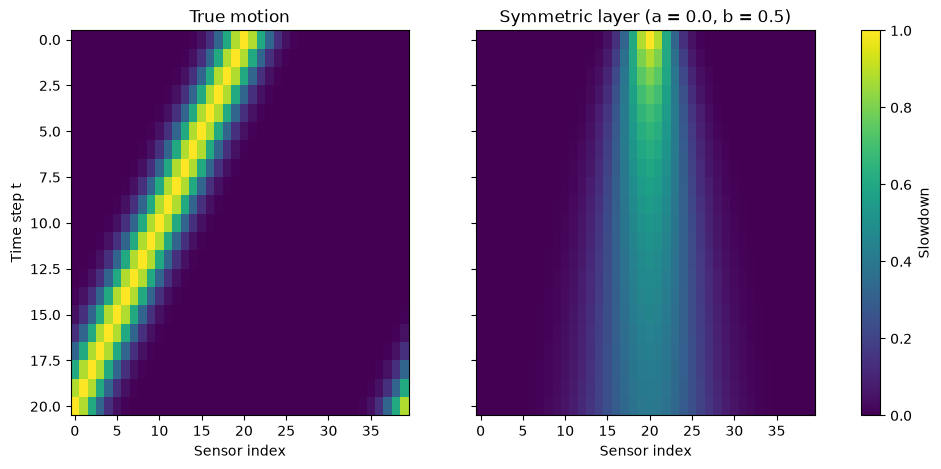

True peak sensor at t=20 : 0
True peak value at t=20 : 1.0
Predicted peak sensor at t=20 : 20
Predicted peak value at t=20 : 0.405
Total slowdown at t=0 : 5.013
Predicted total slowdown at t=20 : 5.013


In [9]:
steps = 20
bump = np.exp(-((sensors - 20) ** 2) / 8)

predicted = [bump]
true = [bump]
for t in range(steps):
    predicted.append(symmetric_layer(predicted[-1], a_fit, b_fit))
    true.append(true_step(true[-1]))
predicted = np.array(predicted)
true = np.array(true)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
titles = ["True motion", f"Symmetric layer (a = {a_fit}, b = {b_fit})"]
for ax, data, title in zip(axes, [true, predicted], titles):
    image = ax.imshow(data, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xlabel("Sensor index")
axes[0].set_ylabel("Time step t")
fig.colorbar(image, ax=axes, label="Slowdown")

os.makedirs("report/figures", exist_ok=True)
fig.savefig("report/figures/q2_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

print("True peak sensor at t=20 :", true[-1].argmax())
print("True peak value at t=20 :", round(true[-1].max(), 3))
print("Predicted peak sensor at t=20 :", predicted[-1].argmax())
print("Predicted peak value at t=20 :", round(predicted[-1].max(), 3))
print("Total slowdown at t=0 :", round(bump.sum(), 3))
print("Predicted total slowdown at t=20 :", round(predicted[-1].sum(), 3))

The true bump moves left one sensor per step and keeps its shape. The symmetric layer keeps the bump centred at sensor 20 and only spreads it out, so it never moves.

### (b) Separate weights for the two directions

$a = 0$, $w_- = 0$, $w_+ = 1$ gives $\hat x_i(t+1) = x_{i+1}(t)$, which is exactly the true rule.

As a 1D convolution: kernel `[0, 0, 1]` for $[x_{i-1}, x_i, x_{i+1}]$, with circular padding (wrap-around) for the ring.

In [10]:
def directional_layer(x, a, w_minus, w_plus):
    return a * x + w_minus * np.roll(x, 1) + w_plus * np.roll(x, -1)


def conv_ring(x, kernel):
    # Circular padding: x_39 goes before x_0 and x_0 goes after x_39
    padded = np.pad(x, 1, mode="wrap")
    windows = np.lib.stride_tricks.sliding_window_view(padded, 3)
    return windows @ kernel


kernel = np.array([0, 0, 1])
rng = np.random.default_rng(0)
snapshots = [bump, x0] + list(rng.random((5, N)))

layer_ok = all(
    np.allclose(directional_layer(x, 0, 0, 1), true_step(x)) for x in snapshots
)
conv_ok = all(np.allclose(conv_ring(x, kernel), true_step(x)) for x in snapshots)

print("Snapshots tested :", len(snapshots))
print("Directional layer exact :", layer_ok)
print("Ring convolution exact :", conv_ok)

Snapshots tested : 7
Directional layer exact : True
Ring convolution exact : True


### (c) Use the previous snapshot, with equal neighbour weights

i. Backward motion: $x_i(t-1) = x_{i-1}(t)$, so **$a = 0,\ b = 1,\ c = -1$** gives $\hat x_i(t+1) = x_{i-1} + x_{i+1} - x_{i-1} = x_{i+1}(t)$.

ii. Forward motion: $x_i(t-1) = x_{i+1}(t)$, so the same coefficients give $x_{i-1}(t)$, which is also correct.

iii. Subtracting $x_i(t-1)$ cancels the neighbour the pattern just moved to, so the direction comes from time.

In [11]:
def history_layer(x_now, x_prev, a, b, c):
    return a * x_now + b * (np.roll(x_now, 1) + np.roll(x_now, -1)) + c * x_prev


a, b, c = 0, 1, -1
x_prev = rng.random(N)

# Backward motion: x_i(t+1) = x_{i+1}(t)
x_now = np.roll(x_prev, -1)
backward_ok = np.allclose(history_layer(x_now, x_prev, a, b, c), np.roll(x_now, -1))

# Forward motion: x_i(t+1) = x_{i-1}(t)
x_now = np.roll(x_prev, 1)
forward_ok = np.allclose(history_layer(x_now, x_prev, a, b, c), np.roll(x_now, 1))

print("Backward motion predicted exactly :", backward_ok)
print("Forward motion predicted exactly :", forward_ok)

Backward motion predicted exactly : True
Forward motion predicted exactly : True
